# EDA sobre `train_70`: edad, experiencia, outliers y fuga de datos (US-06, sección de Brian)

**Issue:** #10 (US-06). **Datos:** solo `data/train_70.csv` (5.647 filas). `val_15` y `test_15` no se abren en este notebook (D-006, D-013).

Este notebook cubre la sección asignada a Brian dentro del EDA completo:

- estructura y calidad de `train_70` (grano, tipos, nulos, duplicados de `ID`);
- **boxplots por clase** para `Age`, `Work_Experience` y `Family_Size`;
- **outliers** con IQR y z-score, y su reparto por segmento;
- **matriz de correlación** de las variables numéricas;
- **revisión de fuga de datos** ("¿alguna columna sabe demasiado?");
- conclusiones escritas a partir de las cifras ejecutadas.

Las figuras se guardan en `reports/figures/` y la tabla de outliers en `reports/outliers_train_70.csv`.

**Cómo reproducir:** ejecutar el notebook completo desde la raíz del repositorio, con el entorno de `requirements.txt`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# --- Configuración visual -------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

# --- Rutas ----------------------------------------------------------------
DATA_PATH = Path("data/train_70.csv")
FIGURES_DIR = Path("reports/figures")
OUTLIERS_PATH = Path("reports/outliers_train_70.csv")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} no existe. Ejecuta primero `python src/split_data.py` "
        "desde la raíz del repositorio."
    )

df = pd.read_csv(DATA_PATH)
SEGMENT_ORDER = ["A", "B", "C", "D"]
NUMERIC_COLS = ["Age", "Work_Experience", "Family_Size"]

print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
print(f"Columnas: {list(df.columns)}")
df.head()


Filas: 5,647 | Columnas: 11
Columnas: ['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession', 'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1', 'Segmentation']


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,460968,Male,Yes,30,No,Doctor,11.0,Average,2.0,Cat_3,A
1,461619,Male,Yes,53,Yes,Executive,NaN,High,3.0,Cat_6,C
2,467217,Female,Yes,79,Yes,Lawyer,NaN,High,2.0,Cat_6,C
3,459338,Male,Yes,88,No,Executive,NaN,Low,NaN,Cat_6,D
4,465826,Male,Yes,45,No,Executive,3.0,Low,9.0,Cat_4,D


## 1. Comprobaciones de estructura y calidad

Grano confirmado: **una fila = un cliente**. `ID` debe ser único y `Segmentation` no puede tener nulos.


In [2]:
assert df["ID"].is_unique, "ID no es único en train_70"
assert df["Segmentation"].notna().all(), "Hay nulos en la variable objetivo"

overview = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(2),
    "únicos": df.nunique(dropna=True),
})
display(overview)

print("\nDistribución de la variable objetivo (train_70):")
class_dist = (
    df["Segmentation"].value_counts(normalize=True)
    .reindex(SEGMENT_ORDER)
    .mul(100)
    .round(2)
)
display(class_dist.to_frame("porcentaje"))
print(f"Total de nulos: {int(df.isna().sum().sum()):,}")


,tipo,nulos,% nulos,únicos
ID,int64,0,0.00,5647
Gender,str,0,0.00,2
Ever_Married,str,99,1.75,2
Age,int64,0,0.00,67
Graduated,str,53,0.94,2
Profession,str,89,1.58,9
Work_Experience,float64,563,9.97,15
Spending_Score,str,0,0.00,3
Family_Size,float64,244,4.32,9
Var_1,str,50,0.89,7



Distribución de la variable objetivo (train_70):


,porcentaje
Segmentation,
A,24.44
B,23.04
C,24.42
D,28.10


Total de nulos: 1,098


## 2. Boxplots por clase (`Age`, `Work_Experience`, `Family_Size`)

El briefing pide histogramas o boxplots por clase. Se usan boxplots porque comparan la mediana y la dispersión entre segmentos en una sola figura.

> Los boxplots excluyen los valores nulos (`NaN`) de cada variable: el eje Y solo representa clientes con dato observado en esa variable.


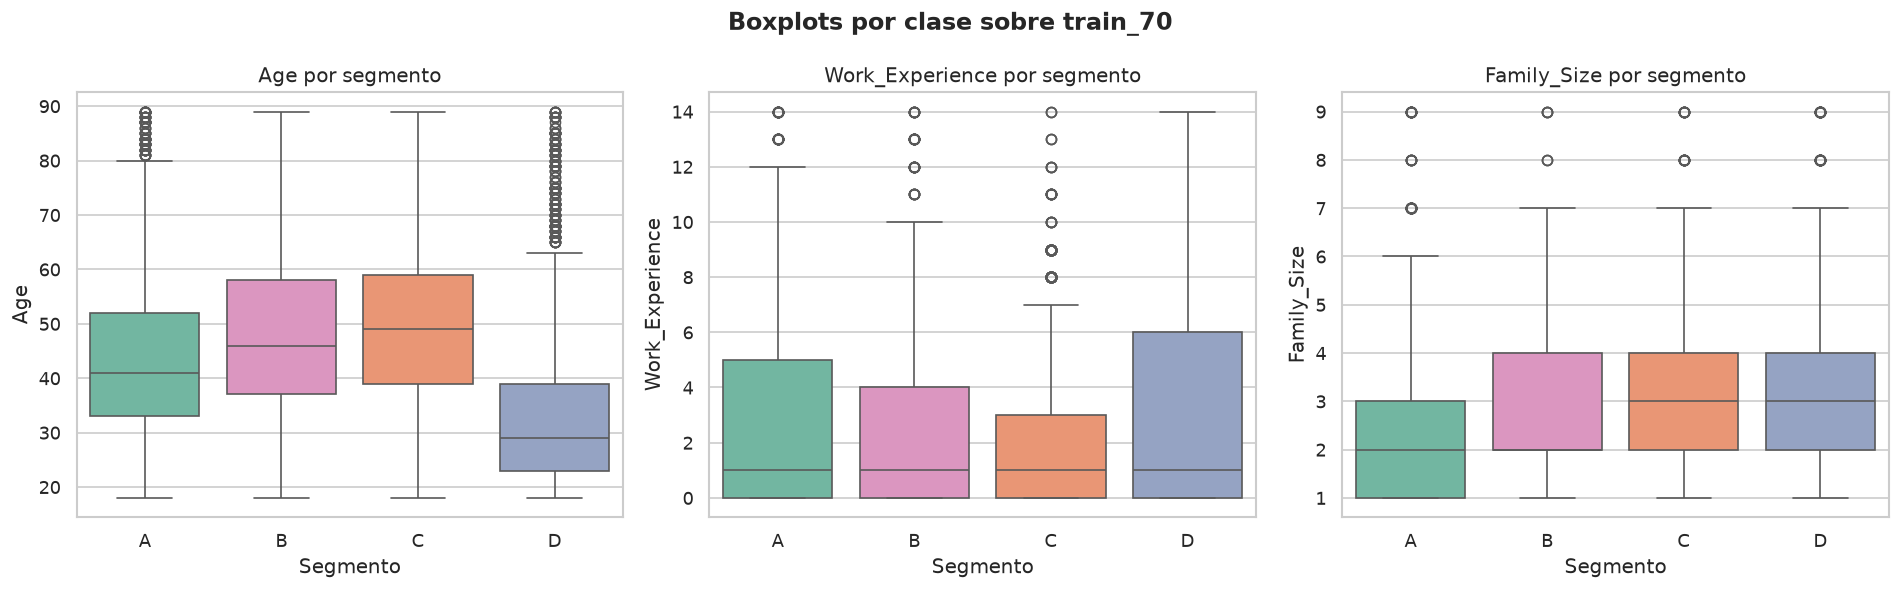

Figura guardada: reports/figures/eda_boxplots_numeric_by_segment.png


In [3]:
fig, axes = plt.subplots(1, len(NUMERIC_COLS), figsize=(16, 5))
for ax, column in zip(axes, NUMERIC_COLS):
    sns.boxplot(
        data=df,
        x="Segmentation",
        y=column,
        order=SEGMENT_ORDER,
        hue="Segmentation",
        palette="Set2",
        legend=False,
        ax=ax,
    )
    ax.set_title(f"{column} por segmento")
    ax.set_xlabel("Segmento")
    ax.set_ylabel(column)

fig.suptitle("Boxplots por clase sobre train_70", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_boxplots_numeric_by_segment.png", bbox_inches="tight")
plt.show()

print("Figura guardada: reports/figures/eda_boxplots_numeric_by_segment.png")


In [4]:
summary_by_segment = (
    df.groupby("Segmentation")[NUMERIC_COLS]
    .agg(["median", "mean", "std", "min", "max"])
    .reindex(SEGMENT_ORDER)
    .round(2)
)
display(summary_by_segment)


Age                       Work_Experience                   \
             median   mean    std min max          median  mean   std  min   
Segmentation                                                                 
A              41.0  44.71  15.99  18  89             1.0  2.89  3.66  0.0   
B              46.0  48.20  14.89  18  89             1.0  2.40  3.28  0.0   
C              49.0  49.58  14.91  18  89             1.0  2.25  3.01  0.0   
D              29.0  33.91  15.99  18  89             1.0  3.03  3.63  0.0   

                   Family_Size                        
               max      median  mean   std  min  max  
Segmentation                                          
A             14.0         2.0  2.49  1.55  1.0  9.0  
B             14.0         2.0  2.68  1.41  1.0  9.0  
C             14.0         3.0  2.95  1.35  1.0  9.0  
D             14.0         3.0  3.21  1.71  1.0  9.0

## 3. Detección de outliers (IQR + z-score)

Un valor se marca como outlier si queda fuera de `Q1 - 1.5·IQR` / `Q3 + 1.5·IQR` o si su `|z| > 3`. Los outliers se **señalan, no se eliminan**: hay que decidir si son señal real o error de datos. En este dataset, `Work_Experience` y `Family_Size` son variables discretas de rango corto, por lo que los "outliers" del IQR suelen ser valores válidos en el extremo de la distribución.


In [5]:
def iqr_bounds(series: pd.Series) -> tuple[float, float]:
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def outlier_table(frame: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    rows = []
    for column in columns:
        series = frame[column].dropna()
        lower, upper = iqr_bounds(series)
        iqr_mask = (series < lower) | (series > upper)

        z = (series - series.mean()) / series.std(ddof=0)
        z_mask = z.abs() > 3

        rows.append(
            {
                "variable": column,
                "n": len(series),
                "q1": series.quantile(0.25),
                "q3": series.quantile(0.75),
                "iqr_lower": lower,
                "iqr_upper": upper,
                "n_iqr": int(iqr_mask.sum()),
                "pct_iqr": round(iqr_mask.mean() * 100, 2),
                "n_zscore": int(z_mask.sum()),
                "pct_zscore": round(z_mask.mean() * 100, 2),
                "min": series.min(),
                "max": series.max(),
            }
        )
    return pd.DataFrame(rows)


outliers = outlier_table(df, NUMERIC_COLS)
display(outliers)

outliers.to_csv(OUTLIERS_PATH, index=False, lineterminator="\n")
print(f"Tabla guardada: {OUTLIERS_PATH}")


,variable,n,q1,q3,iqr_lower,iqr_upper,n_iqr,pct_iqr,n_zscore,pct_zscore,min,max
0,Age,5647,31.0,53.0,-2.0,86.0,72,1.28,0,0.00,18.0,89.0
1,Work_Experience,5084,0.0,4.0,-6.0,10.0,142,2.79,68,1.34,0.0,14.0
2,Family_Size,5403,2.0,4.0,-1.0,7.0,65,1.20,65,1.20,1.0,9.0


Tabla guardada: reports/outliers_train_70.csv


In [6]:
# Reparto de outliers IQR por segmento: ¿se concentran en algún segmento?
rows = []
for column in NUMERIC_COLS:
    series = df[column]
    lower, upper = iqr_bounds(series.dropna())
    mask = (series < lower) | (series > upper)
    counts = df.loc[mask, "Segmentation"].value_counts().reindex(SEGMENT_ORDER, fill_value=0)
    totals = df["Segmentation"].value_counts().reindex(SEGMENT_ORDER)
    pct = (counts / totals * 100).round(2)
    row = {"variable": column}
    row.update({f"{seg}_n": int(counts[seg]) for seg in SEGMENT_ORDER})
    row.update({f"{seg}_%": float(pct[seg]) for seg in SEGMENT_ORDER})
    rows.append(row)

display(pd.DataFrame(rows))


,variable,A_n,B_n,C_n,D_n,A_%,B_%,C_%,D_%
0,Age,27,12,21,12,1.96,0.92,1.52,0.76
1,Work_Experience,55,29,14,44,3.99,2.23,1.02,2.77
2,Family_Size,16,5,15,29,1.16,0.38,1.09,1.83


### Rangos plausibles y decisión sobre los outliers

Antes de decidir si un outlier es un error, se comprueba que los valores estén dentro de un rango de negocio plausible. En este dataset los máximos observados son valores reales del formulario de cliente, no errores de carga.

In [7]:
plausible_ranges = {
    "Age": (0, 120),
    "Work_Experience": (0, 50),
    "Family_Size": (0, 20),
}

rows = []
for column, (lower, upper) in plausible_ranges.items():
    series = df[column].dropna()
    rows.append(
        {
            "variable": column,
            "min_observado": series.min(),
            "max_observado": series.max(),
            "rango_plausible": f"[{lower}, {upper}]",
            "dentro_de_rango": bool(series.between(lower, upper).all()),
        }
    )

ranges = pd.DataFrame(rows)
display(ranges)
print(
    "Decisión: no se elimina ningún outlier; todos los valores están dentro "
    "del rango plausible y se documentan."
)


,variable,min_observado,max_observado,rango_plausible,dentro_de_rango
0,Age,18.0,89.0,"[0, 120]",True
1,Work_Experience,0.0,14.0,"[0, 50]",True
2,Family_Size,1.0,9.0,"[0, 20]",True


Decisión: no se elimina ningún outlier; todos los valores están dentro del rango plausible y se documentan.


## 4. Matriz de correlación (variables numéricas)

Se calcula Pearson entre `Age`, `Work_Experience` y `Family_Size`. Un par con `|r| >= 0.8` se marca como posible multicolinealidad.


,Age,Work_Experience,Family_Size
Age,1.000,-0.195,-0.276
Work_Experience,-0.195,1.000,-0.054
Family_Size,-0.276,-0.054,1.000


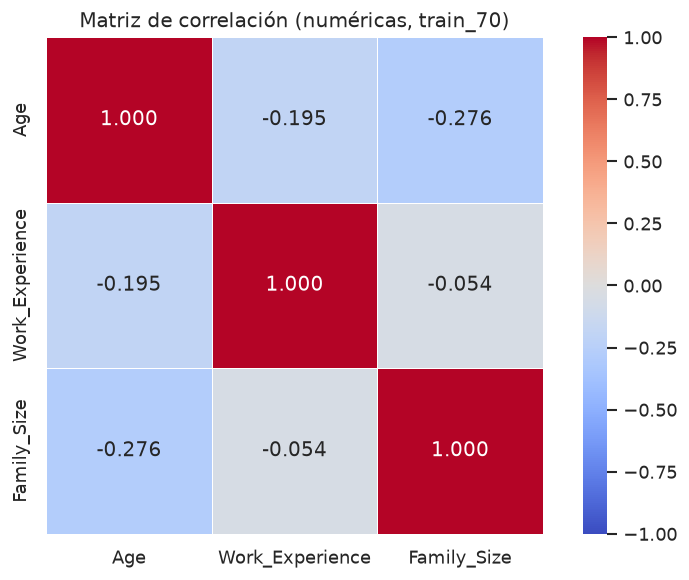

Pares con |r| >= 0.8: ninguno


In [8]:
corr = df[NUMERIC_COLS].corr(method="pearson").round(3)
display(corr)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Matriz de correlación (numéricas, train_70)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_correlation_matrix.png", bbox_inches="tight")
plt.show()

strong_pairs = []
for i, first in enumerate(NUMERIC_COLS):
    for second in NUMERIC_COLS[i + 1:]:
        value = corr.loc[first, second]
        if abs(value) >= 0.8:
            strong_pairs.append((first, second, value))

print("Pares con |r| >= 0.8:", strong_pairs if strong_pairs else "ninguno")


## 5. Revisión de fuga de datos ("¿alguna columna sabe demasiado?")

Se comprueba:

1. que `ID` no sea una feature (es un identificador);
2. la asociación de cada predictor con `Segmentation`, con una medida adecuada al tipo:
   - **V de Cramér** para variables categóricas;
   - **eta cuadrado** (razón de correlación) para variables numéricas.

Una asociación cercana a 1 indicaría que la columna casi determina el segmento (posible fuga). Valores altos pero no perfectos son esperables: el EDA describe asociación, no causalidad.


In [9]:
def cramers_v(x: pd.Series, y: pd.Series) -> float:
    table = pd.crosstab(x, y)
    if table.size == 0:
        return float("nan")
    observed = table.to_numpy(dtype=float)
    total = observed.sum()
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / total
    with np.errstate(divide="ignore", invalid="ignore"):
        chi2 = np.nansum((observed - expected) ** 2 / expected)
    denominator = total * (min(observed.shape) - 1)
    return float(np.sqrt(chi2 / denominator)) if denominator > 0 else float("nan")


def eta_squared(values: pd.Series, groups: pd.Series) -> float:
    frame = pd.DataFrame({"value": values, "group": groups}).dropna()
    if frame.empty:
        return float("nan")
    grand_mean = frame["value"].mean()
    ss_total = ((frame["value"] - grand_mean) ** 2).sum()
    ss_between = sum(
        len(group) * (group["value"].mean() - grand_mean) ** 2
        for _, group in frame.groupby("group")
    )
    return float(ss_between / ss_total) if ss_total > 0 else float("nan")


predictors = [c for c in df.columns if c not in ("ID", "Segmentation")]
association_rows = []
for column in predictors:
    if pd.api.types.is_numeric_dtype(df[column]) and column in NUMERIC_COLS:
        strength = eta_squared(df[column], df["Segmentation"])
        measure = "eta² (numérica)"
    else:
        strength = cramers_v(df[column], df["Segmentation"])
        measure = "V de Cramér"
    association_rows.append(
        {
            "variable": column,
            "medida": measure,
            "asociación": round(strength, 4),
            "¿cerca de determinista?": "SÍ - revisar" if strength >= 0.8 else "no",
        }
    )

association = pd.DataFrame(association_rows).sort_values("asociación", ascending=False)
display(association)

print("\nComprobaciones de fuga:")
print("- ID es único y no se usa como feature:", df["ID"].is_unique)
print("- ¿Hay alguna asociación >= 0.8 con el target?",
      bool((association["asociación"] >= 0.8).any()))


,variable,medida,asociación,¿cerca de determinista?
1,Ever_Married,V de Cramér,0.4085,no
3,Graduated,V de Cramér,0.3495,no
4,Profession,V de Cramér,0.3302,no
6,Spending_Score,V de Cramér,0.3024,no
2,Age,eta² (numérica),0.1440,no
8,Var_1,V de Cramér,0.1113,no
0,Gender,V de Cramér,0.0354,no
7,Family_Size,eta² (numérica),0.0322,no
5,Work_Experience,eta² (numérica),0.0092,no



Comprobaciones de fuga:
- ID es único y no se usa como feature: True
- ¿Hay alguna asociación >= 0.8 con el target? False


### 5.1 Contraste de hipótesis para las numéricas (Kruskal-Wallis)

La eta² mide la fuerza de la asociación; Kruskal-Wallis contrasta si las distribuciones de cada numérica difieren entre segmentos (H₀: mismas distribuciones). Un p-valor pequeño indica que la variable separa segmentos.

In [10]:
from scipy.stats import kruskal

kw_rows = []
for column in NUMERIC_COLS:
    groups = [
        group[column].dropna().to_numpy()
        for _, group in df.groupby("Segmentation")
    ]
    statistic, p_value = kruskal(*groups)
    kw_rows.append(
        {
            "variable": column,
            "H": round(float(statistic), 3),
            "p_value": float(p_value),
            "¿difiere entre segmentos?": "sí" if p_value < 0.05 else "no",
        }
    )

kw = pd.DataFrame(kw_rows)
display(kw)


,variable,H,p_value,¿difiere entre segmentos?
0,Age,1120.025,1.646697e-242,sí
1,Work_Experience,29.986,1.389178e-06,sí
2,Family_Size,205.612,2.585069e-44,sí


### 5.2 Prueba directa: un árbol de una sola variable

Para cada feature se entrena un `DecisionTreeClassifier(max_depth=1)` con validación cruzada estratificada de 5 folds sobre `train_70`. Sirve como prueba directa de cuánto sabe cada variable **por sí sola** del segmento: si una sola variable diera una accuracy muy alta, sería una fuga.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

from src.config import RANDOM_STATE

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

tree_rows = []
for column in predictors:
    if column in NUMERIC_COLS:
        prep = ColumnTransformer(
            [("num", SimpleImputer(strategy="median"), [column])]
        )
    else:
        prep = ColumnTransformer(
            [
                (
                    "cat",
                    Pipeline(
                        [
                            ("imp", SimpleImputer(strategy="most_frequent")),
                            ("enc", OneHotEncoder(handle_unknown="ignore")),
                        ]
                    ),
                    [column],
                )
            ]
        )
    model = Pipeline(
        [
            ("prep", prep),
            ("tree", DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)),
        ]
    )
    scores = cross_val_score(
        model,
        df[[column]],
        df["Segmentation"],
        cv=cv,
        scoring="accuracy",
    )
    tree_rows.append(
        {
            "variable": column,
            "accuracy_cv_media": round(float(scores.mean()), 4),
            "accuracy_cv_std": round(float(scores.std()), 4),
        }
    )

tree_table = pd.DataFrame(tree_rows).sort_values(
    "accuracy_cv_media", ascending=False
)
display(tree_table)


,variable,accuracy_cv_media,accuracy_cv_std
6,Spending_Score,0.4059,0.0076
2,Age,0.3974,0.0089
1,Ever_Married,0.3896,0.0071
3,Graduated,0.3733,0.0052
4,Profession,0.3512,0.0029
7,Family_Size,0.3053,0.0114
8,Var_1,0.3016,0.0135
0,Gender,0.2810,0.0004
5,Work_Experience,0.2810,0.0004


### 5.3 `ID` frente al segmento

`ID` es un identificador y nunca se usa como feature. Aun así se comprueba que no tenga relación con el segmento (si la tuviera, sería una fuga). Se usa Kruskal-Wallis sobre `ID` agrupado por segmento.

In [12]:
id_groups = [
    group["ID"].dropna().to_numpy()
    for _, group in df.groupby("Segmentation")
]
id_stat, id_p = kruskal(*id_groups)

print(f"Kruskal-Wallis ID vs Segmentation: H={id_stat:.3f}, p={id_p:.4f}")
print(
    "Conclusión:",
    "sin relación significativa (p >= 0.05)"
    if id_p >= 0.05
    else "relación significativa (revisar)",
)


Kruskal-Wallis ID vs Segmentation: H=3.662, p=0.3004
Conclusión: sin relación significativa (p >= 0.05)


## 6. Nulos por segmento (¿el nulo es informativo?)

Si los nulos de una variable se concentran en un segmento, el hecho de que falte el dato ya aporta información (y puede ser una fuga sutil). Se compara la distribución de segmentos entre las filas con nulo y el total para cada variable con nulos.

In [13]:
null_rows = []
for column in df.columns:
    n_null = int(df[column].isna().sum())
    if n_null == 0:
        continue

    mask = df[column].isna()
    dist = (
        df.loc[mask, "Segmentation"]
        .value_counts(normalize=True)
        .reindex(SEGMENT_ORDER, fill_value=0)
        .mul(100)
        .round(2)
    )
    row = {
        "variable": column,
        "n_nulos": n_null,
        "pct_nulos": round(n_null / len(df) * 100, 2),
    }
    row.update({f"{seg}_%": float(dist[seg]) for seg in SEGMENT_ORDER})
    null_rows.append(row)

null_by_segment = pd.DataFrame(null_rows)
display(null_by_segment)

print("\nDistribución global de segmentos en train_70:")
display(
    df["Segmentation"]
    .value_counts(normalize=True)
    .reindex(SEGMENT_ORDER)
    .mul(100)
    .round(2)
    .to_frame("porcentaje")
)


,variable,n_nulos,pct_nulos,A_%,B_%,C_%,D_%
0,Ever_Married,99,1.75,24.24,23.23,16.16,36.36
1,Graduated,53,0.94,30.19,18.87,26.42,24.53
2,Profession,89,1.58,24.72,21.35,12.36,41.57
3,Work_Experience,563,9.97,21.49,24.87,17.94,35.70
4,Family_Size,244,4.32,26.64,12.30,13.93,47.13
5,Var_1,50,0.89,26.00,14.00,30.00,30.00



Distribución global de segmentos en train_70:


,porcentaje
Segmentation,
A,24.44
B,23.04
C,24.42
D,28.10


## 7. Conclusiones (basadas en las cifras ejecutadas)

Todas las afirmaciones siguientes salen de las tablas y figuras de arriba, calculadas sobre `train_70` (5.647 filas). Describen asociación, no causalidad.

- **Edad:** es la variable numérica que más separa los segmentos (`eta² = 0.144`; Kruskal-Wallis p ≈ 1.6e-242). **D es claramente más joven** (mediana 29, media 33,9) que **A** (mediana 41, media 44,7), **B** (mediana 46, media 48,2) y **C** (mediana 49, media 49,6).
- **Experiencia laboral:** las medianas son iguales en los cuatro segmentos (1,0) y las medias son muy parecidas (2,25–3,03). Kruskal-Wallis sale significativo (p ≈ 1.4e-06), pero la **fuerza** de la asociación es prácticamente nula (`eta² = 0.009`): con 5.647 filas, un test puede ser significativo sin que la variable discrimine de forma útil. En el árbol de una variable, `Work_Experience` obtiene 0.2810, exactamente el baseline: por sí sola no aporta.
- **Tamaño de familia:** medianas 2 (A, B) y 3 (C, D); `eta² = 0.032` (Kruskal-Wallis p ≈ 2.6e-44). Aporta algo más que la experiencia, pero menos que la edad; en el árbol de una variable obtiene 0.3053.
- **Outliers:** el IQR marca 72 valores en `Age` (1,28 %), 142 en `Work_Experience` (2,79 %) y 65 en `Family_Size` (1,20 %). El z-score solo marca valores en `Work_Experience` (68; 1,34 %) y `Family_Size` (65; 1,20 %). Los rangos observados (`Age` 18–89, `Work_Experience` 0–14, `Family_Size` 1–9) están **dentro de rangos plausibles** (0–120, 0–50, 0–20), así que son valores reales y **no se eliminan**; se documentan en `reports/outliers_train_70.csv`.
- **Reparto de outliers por segmento:** los de `Age` se concentran algo más en A (1,96 %) y C (1,52 %); los de `Work_Experience` en A (3,99 %) y D (2,77 %); los de `Family_Size` en D (1,83 %). Porcentajes pequeños; no cambian la conclusión.
- **Correlación:** no hay ningún par con `|r| >= 0.8`. Las correlaciones más altas son `Age`–`Family_Size` (−0,276) y `Age`–`Work_Experience` (−0,195); `Work_Experience`–`Family_Size` es −0,054. **No hay multicolinealidad grave** entre las numéricas.
- **Fuga de datos (asociación):** ninguna variable alcanza una asociación cercana a 1 con el segmento (`>= 0.8`). Las más asociadas son `Ever_Married` (V de Cramér 0,409), `Graduated` (0,350), `Profession` (0,330), `Spending_Score` (0,302) y `Age` (eta² 0,144). `ID` no se usa como feature y su test frente al segmento da **p = 0,3004**, sin relación significativa.
- **Fuga de datos (prueba directa):** el árbol de una sola variable confirma que ninguna feature es determinista. La mejor es `Spending_Score` (accuracy CV 0,406), seguida de `Age` (0,397), `Ever_Married` (0,390), `Graduated` (0,373) y `Profession` (0,351). `Gender` y `Work_Experience` empatan con el baseline (0,281). Un máximo de ~0,41 está muy lejos de una fuga; el segmento no es derivable de una sola columna.
- **Nulos por segmento (el nulo es informativo):** los nulos se concentran en **D**: `Family_Size` 47,13 % D (frente al 28,10 % global), `Profession` 41,57 % D, `Ever_Married` 36,36 % D y `Work_Experience` 35,70 % D. El hecho de que falte el dato aporta señal. D-011 ya añade indicadores para `Work_Experience` y `Family_Size`; para las categóricas conviene valorar un indicador de nulo antes de imputar, sin cambiar el CSV.
- **Implicaciones para el modelado:** `Spending_Score` y `Age` son las variables individuales más informativas; `Ever_Married`, `Graduated` y `Profession` aportan de forma moderada; `Family_Size` y `Var_1` algo menos; `Gender` y `Work_Experience` no superan el baseline por sí solas. Al no haber fuga, se pueden usar todas las features (excepto `ID`) y dejar que el Pipeline y la validación decidan su peso real.


## 8. Checklist EDA (programmatic-eda)

- [x] Carga sin errores y grano identificado (1 fila = 1 cliente).
- [x] Recuento de filas y columnas confirmado.
- [x] `ID` verificado como único y sin relación con el segmento (p = 0,3004).
- [x] Tipos de datos revisados.
- [x] Nulos revisados por columna y por segmento.
- [x] Duplicados de `ID` comprobados.
- [x] Rangos numéricos plausibles verificados (`Age` 18–89, `Work_Experience` 0–14, `Family_Size` 1–9).
- [x] Outliers revisados con IQR y z-score; no se eliminan, se documentan.
- [x] Distribuciones numéricas por clase (boxplots, sin nulos).
- [x] Correlaciones numéricas y pares fuertes marcados.
- [x] Asociación de cada predictor con el target revisada (eta² / V de Cramér).
- [x] Contraste de hipótesis con Kruskal-Wallis para las numéricas.
- [x] Prueba directa con un árbol de una sola variable por feature.
- [x] Nulos por segmento analizados (concentración en D).
- [x] Conclusiones escritas (sección 7).
